#### Zihang's Code [Task 3, 4, 5, 7]

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

#DATA_DIR = Path('/Users/wang/Downloads/AO')
home_path = 'C:/Users/cathe/Documents/LMU Munich Masters/Observational_Instrumental_Lab_WS2627_LMU_Munich/Exp_1_Adaptive_Optics'
DATA_DIR = Path(home_path+'/Data/Tues0') # C:\Users\cathe\Documents\LMU Munich Masters\Observational_Instrumental_Lab_WS2627_LMU_Munich\Exp_1_Adaptive_Optics\Data\Tues0
WAVELENGTH_UM = 0.635

assert DATA_DIR.is_dir(), f'Data directory not found: {DATA_DIR}'
print(f'Using data directory: {DATA_DIR}')

Using data directory: C:\Users\cathe\Documents\LMU Munich Masters\Observational_Instrumental_Lab_WS2627_LMU_Munich\Exp_1_Adaptive_Optics\Data\Tues0


In [2]:
def load_grid(filename):
    """Load a tab-separated camera array with decimal commas."""
    rows = []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if fields:
            rows.append([np.nan if x == 'NaN' else float(x.replace(',', '.')) for x in fields])
    return np.asarray(rows, dtype=float)

def load_wfe(filename):
    """Return a dataframe with time, P2V, and RMS from the WFS export."""
    rows = []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if len(fields) >= 4:
            try:
                rows.append([float(fields[0].replace(',', '.')),
                             float(fields[1].replace(',', '.')),
                             float(fields[3].replace(',', '.'))])
            except ValueError:  # skip the header row
                pass
    return pd.DataFrame(rows, columns=['time', 'p2v_um', 'rms_um'])

def fwhm(profile):
    """
    FWHM in pixels from a 1D profile. Background is the median of the
    first and last 10% of pixels; half-height crossings use linear interpolation.
    """
    profile = np.asarray(profile, dtype=float)
    edge = max(5, len(profile) // 10)
    background = np.median(np.r_[profile[:edge], profile[-edge:]])
    peak_index = int(np.nanargmax(profile))
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)

    left_candidates = np.where(profile[:peak_index] < half)[0]
    right_candidates = np.where(profile[peak_index + 1:] < half)[0]
    if len(left_candidates) == 0 or len(right_candidates) == 0:
        raise ValueError('The profile does not cross half maximum on both sides.')

    left_index = left_candidates[-1]
    right_index = peak_index + 1 + right_candidates[0]
    left_crossing = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right_crossing = (right_index - 1
                      + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1]))
    return dict(width_px=right_crossing - left_crossing, left_px=left_crossing,
                right_px=right_crossing, peak_px=peak_index, peak=peak,
                background=background, half=half)

def analyse_state(label, wfe_file, image_file):
    wfe = load_wfe(wfe_file)
    image = load_grid(image_file)
    peak_row, peak_col = np.unravel_index(np.nanargmax(image), image.shape)
    x_profile = image[peak_row, :]
    y_profile = image[:, peak_col]
    rms_mean = wfe['rms_um'].mean()
    return dict(
        label=label, wfe=wfe, image=image, peak_row=peak_row, peak_col=peak_col,
        x_profile=x_profile, y_profile=y_profile, x_fwhm=fwhm(x_profile), y_fwhm=fwhm(y_profile),
        p2v_mean_um=wfe['p2v_um'].mean(), p2v_sd_um=wfe['p2v_um'].std(ddof=1),
        rms_mean_um=rms_mean, rms_sd_um=wfe['rms_um'].std(ddof=1),
        strehl_marechal=np.exp(-(2 * np.pi * rms_mean / WAVELENGTH_UM) ** 2),
    )

In [3]:
task3 = analyse_state('Task 3 - uncorrected',
                      'Task3_stat_wavefront_err.txt',
                      'Task3_FWHM_raw_data.txt')
task4 = analyse_state('Task 4 - corrected',
                      'Task4_stat_wavefront_err_corr_sys.txt',
                      'Task4_FWHM_raw_data_corr_sys.txt')

summary = pd.DataFrame([
    {'State': task3['label'], 'P2V WFE (um)': task3['p2v_mean_um'], 'P2V SD (um)': task3['p2v_sd_um'],
     'RMS WFE (um)': task3['rms_mean_um'], 'RMS SD (um)': task3['rms_sd_um'],
     'Strehl (Marechal)': task3['strehl_marechal'],
     'FWHM x (px)': task3['x_fwhm']['width_px'], 'FWHM y (px)': task3['y_fwhm']['width_px'],
     'Camera array': f"{task3['image'].shape[0]} x {task3['image'].shape[1]}"},
    {'State': task4['label'], 'P2V WFE (um)': task4['p2v_mean_um'], 'P2V SD (um)': task4['p2v_sd_um'],
     'RMS WFE (um)': task4['rms_mean_um'], 'RMS SD (um)': task4['rms_sd_um'],
     'Strehl (Marechal)': task4['strehl_marechal'],
     'FWHM x (px)': task4['x_fwhm']['width_px'], 'FWHM y (px)': task4['y_fwhm']['width_px'],
     'Camera array': f"{task4['image'].shape[0]} x {task4['image'].shape[1]}"},
])

display(summary.style.format({
    'P2V WFE (um)': '{:.4f}', 'P2V SD (um)': '{:.4f}',
    'RMS WFE (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'Strehl (Marechal)': '{:.3g}', 'FWHM x (px)': '{:.1f}', 'FWHM y (px)': '{:.1f}',
}))

print(f"RMS reduction factor: {task3['rms_mean_um'] / task4['rms_mean_um']:.2f}x")
print(f"P2V reduction factor: {task3['p2v_mean_um'] / task4['p2v_mean_um']:.2f}x")

,State,P2V WFE (um),P2V SD (um),RMS WFE (um),RMS SD (um),Strehl (Marechal),FWHM x (px),FWHM y (px),Camera array
0,Task 3 - uncorrected,12.8096,0.0209,3.26941,0.00529,0,25.0,35.0,101 x 101
1,Task 4 - corrected,0.3398,0.0098,0.07597,0.00321,0.568,30.0,34.0,391 x 427


RMS reduction factor: 43.04x
P2V reduction factor: 37.70x


In [4]:
 # strehle ratio uncertainty = 2*RMS*[ (2*pi*RMS/lambda)^2 ] *S*err_RMS
errS_task3 = 2*task3['rms_mean_um']*((2*np.pi*task3['rms_mean_um']/WAVELENGTH_UM)**2)*task3['strehl_marechal']*task3['rms_sd_um']
print('Task3', task3['strehl_marechal'], errS_task3)
errS_task4 = 2*task4['rms_mean_um']*((2*np.pi*task4['rms_mean_um']/WAVELENGTH_UM)**2)*task4['strehl_marechal']*task4['rms_sd_um']
print(f'Task4: S = {task4['strehl_marechal']} ± {errS_task4}')
print(f'Task4: S = {task4['strehl_marechal']:.5f} ± {errS_task4:.2g}')

Task3 0.0 0.0
Task4: S = 0.5683355979493431 ± 0.0001565603478176842
Task4: S = 0.56834 ± 0.00016


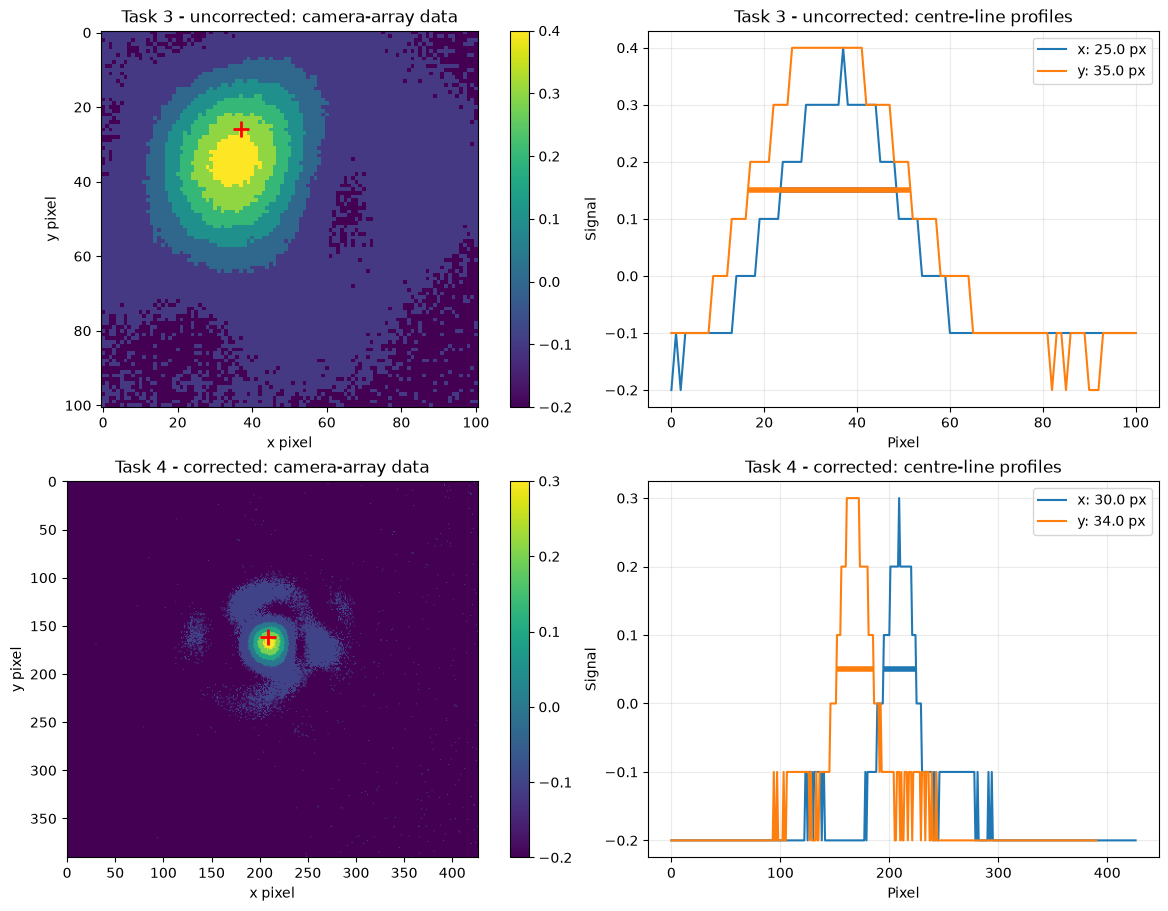

In [5]:
# Camera-array heatmaps and central FWHM profiles
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, state in enumerate([task3, task4]):
    ax = axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f"{state['label']}: camera-array data")
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px")
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
    ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal')
    ax.legend(); ax.grid(alpha=0.25)
plt.show()

,Zernike order,Mean coefficient,SD of fluctuation,Peak-to-peak fluctuation
0,1,+0.0477,0.0044,0.0100
1,3,+0.0185,0.0038,0.0100
2,2,-0.0608,0.0028,0.0100
3,5,+0.0292,0.0028,0.0100
4,11,-0.0300,0.0000,0.0000
5,8,-0.0200,0.0000,0.0000
6,7,+0.0200,0.0000,0.0000
7,6,-0.0200,0.0000,0.0000
8,4,+0.0100,0.0000,0.0000
9,9,-0.0100,0.0000,0.0000


Task 5 snapshots: 13; Zernike modes per snapshot: 20
Largest fluctuations: Z1 (SD 0.0044), Z3 (SD 0.0038), Z2 (SD 0.0028), Z5 (SD 0.0028)


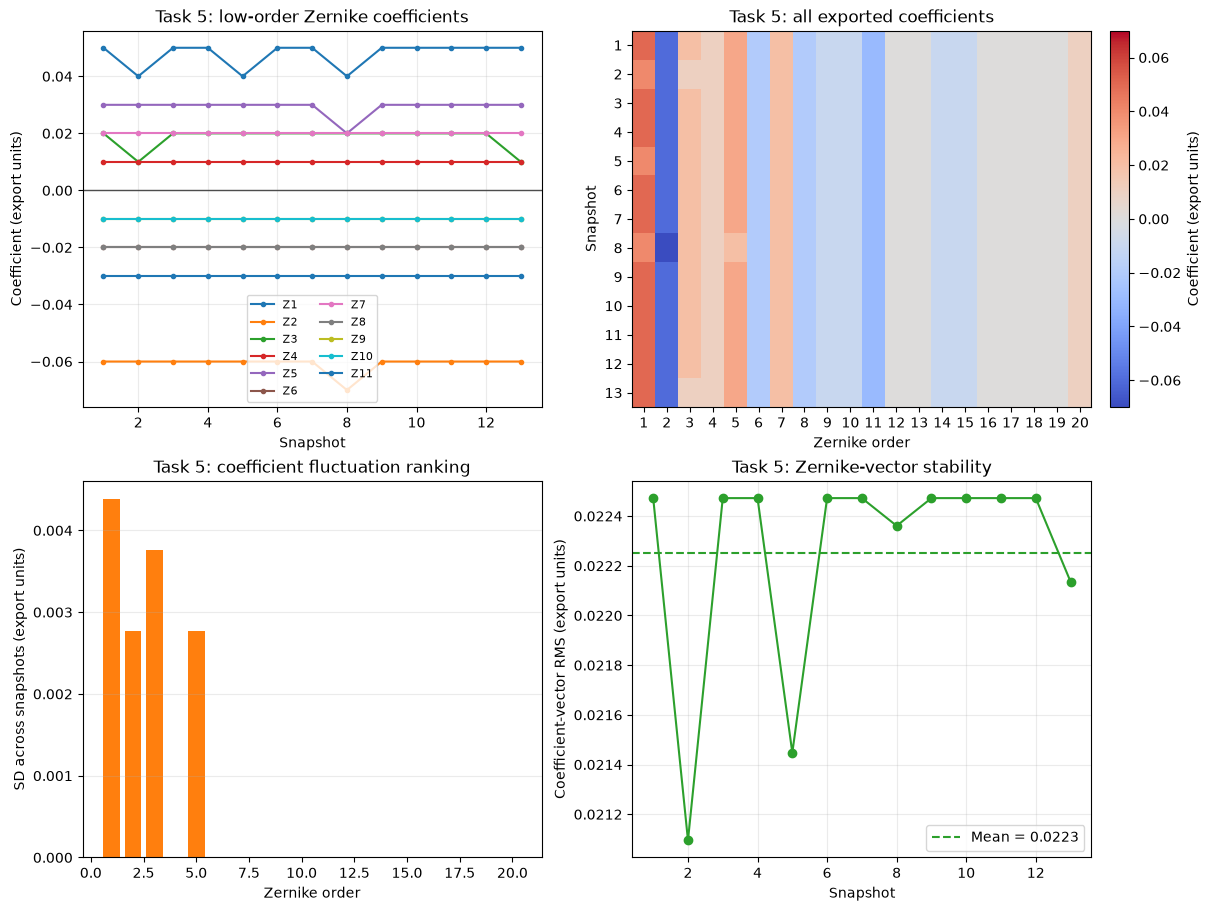

In [6]:
# TASK 5 - system stability
def load_zernike_snapshots_task5(filename):
    snapshots, current = [], []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x.strip() for x in line.split('\t') if x.strip()]
        try:
            order = int(fields[0])
            value = float(fields[1].replace(',', '.'))
        except (IndexError, ValueError):
            if current:
                snapshots.append(current)
                current = []
            continue
        if order == 1 and current:
            snapshots.append(current)
            current = []
        current.append((order, value))
    if current:
        snapshots.append(current)
    return [pd.DataFrame(block, columns=['zernike_order', 'coefficient']) for block in snapshots]

task5_snapshots = load_zernike_snapshots_task5('Task5_System_stability.txt')
assert len(task5_snapshots) >= 10, 'Task 5 requires at least 10 snapshots.'
task5_orders = task5_snapshots[0]['zernike_order'].to_numpy()
assert all(snapshot['zernike_order'].equals(task5_snapshots[0]['zernike_order'])
           for snapshot in task5_snapshots), 'Zernike orders differ between snapshots.'
task5_coefficients = np.vstack([snapshot['coefficient'].to_numpy() for snapshot in task5_snapshots])
task5_snapshot_rms = np.sqrt(np.mean(task5_coefficients ** 2, axis=1))

task5_statistics = pd.DataFrame({
    'Zernike order': task5_orders,
    'Mean coefficient': task5_coefficients.mean(axis=0),
    'SD of fluctuation': task5_coefficients.std(axis=0, ddof=1),
    'Peak-to-peak fluctuation': np.ptp(task5_coefficients, axis=0),
})
task5_ranked_statistics = task5_statistics.sort_values('SD of fluctuation', ascending=False).reset_index(drop=True)
display(task5_ranked_statistics.style.format({
    'Mean coefficient': '{:+.4f}',
    'SD of fluctuation': '{:.4f}',
    'Peak-to-peak fluctuation': '{:.4f}',
}))

task5_top_modes = task5_ranked_statistics.head(4)
task5_top_non_piston = task5_ranked_statistics.query('`Zernike order` != 1').head(3)
print(f'Task 5 snapshots: {len(task5_snapshots)}; Zernike modes per snapshot: {len(task5_orders)}')
print('Largest fluctuations: ' + ', '.join(
    f"Z{int(row['Zernike order'])} (SD {row['SD of fluctuation']:.4f})"
    for _, row in task5_top_modes.iterrows()))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
snapshot_number = np.arange(1, len(task5_snapshots) + 1)

ax = axes[0, 0]
for index, order in enumerate(task5_orders[:11]):
    ax.plot(snapshot_number, task5_coefficients[:, index], 'o-', ms=3, label=f'Z{order}')
ax.axhline(0, color='0.3', lw=1)
ax.set(title='Task 5: low-order Zernike coefficients', xlabel='Snapshot',
       ylabel='Coefficient (export units)')
ax.grid(alpha=0.25); ax.legend(ncol=2, fontsize=8)

ax = axes[0, 1]
coefficient_limit = max(np.abs(task5_coefficients).max(), 0.01)
im = ax.imshow(task5_coefficients, aspect='auto', cmap='coolwarm',
               vmin=-coefficient_limit, vmax=coefficient_limit)
ax.set(title='Task 5: all exported coefficients', xlabel='Zernike order', ylabel='Snapshot')
ax.set_xticks(np.arange(len(task5_orders))); ax.set_xticklabels(task5_orders)
ax.set_yticks(np.arange(len(task5_snapshots))); ax.set_yticklabels(snapshot_number)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Coefficient (export units)')

ax = axes[1, 0]
top_orders = set(task5_top_modes['Zernike order'])
colours = ['tab:orange' if order in top_orders else 'tab:blue' for order in task5_orders]
ax.bar(task5_orders, task5_statistics['SD of fluctuation'], color=colours)
ax.set(title='Task 5: coefficient fluctuation ranking', xlabel='Zernike order',
       ylabel='SD across snapshots (export units)')
ax.grid(axis='y', alpha=0.25)

ax = axes[1, 1]
ax.plot(snapshot_number, task5_snapshot_rms, 'o-', color='tab:green')
ax.axhline(task5_snapshot_rms.mean(), color='tab:green', ls='--',
           label=f'Mean = {task5_snapshot_rms.mean():.4f}')
ax.set(title='Task 5: Zernike-vector stability', xlabel='Snapshot',
       ylabel='Coefficient-vector RMS (export units)')
ax.grid(alpha=0.25); ax.legend()
plt.show()

,State,Samples,P2V mean (um),P2V SD (um),RMS mean (um),RMS SD (um),RMS min-max (um)
0,Observed low-WFE state (corrected),28,0.07297,0.00820,0.01060,0.00176,"(0.00871, 0.01572)"
1,Observed high-WFE state,91,12.14470,0.20738,3.07692,0.05840,"(2.84197, 3.12090)"


RMS reduction from the observed high- to low-WFE state: 290.3x
Underflow/sentinel WFE samples excluded from statistics: 45
Science-camera text export has non-zero signal: False
Science-camera export identical to wave-front map: True


,FWHM source,Peak plotted value (%),FWHM x (data px),FWHM y (data px)
0,Task7.tif rendered MATLAB figure (provisional),84.468,34.6,50.0


Task 7 provisional FWHM is measured from the rendered TIFF; replace it with a raw science-camera frame after remeasurement.
Zernike stability snapshots: 14; modes per snapshot: 20
Largest recorded Zernike coefficient magnitude: 0.010 um


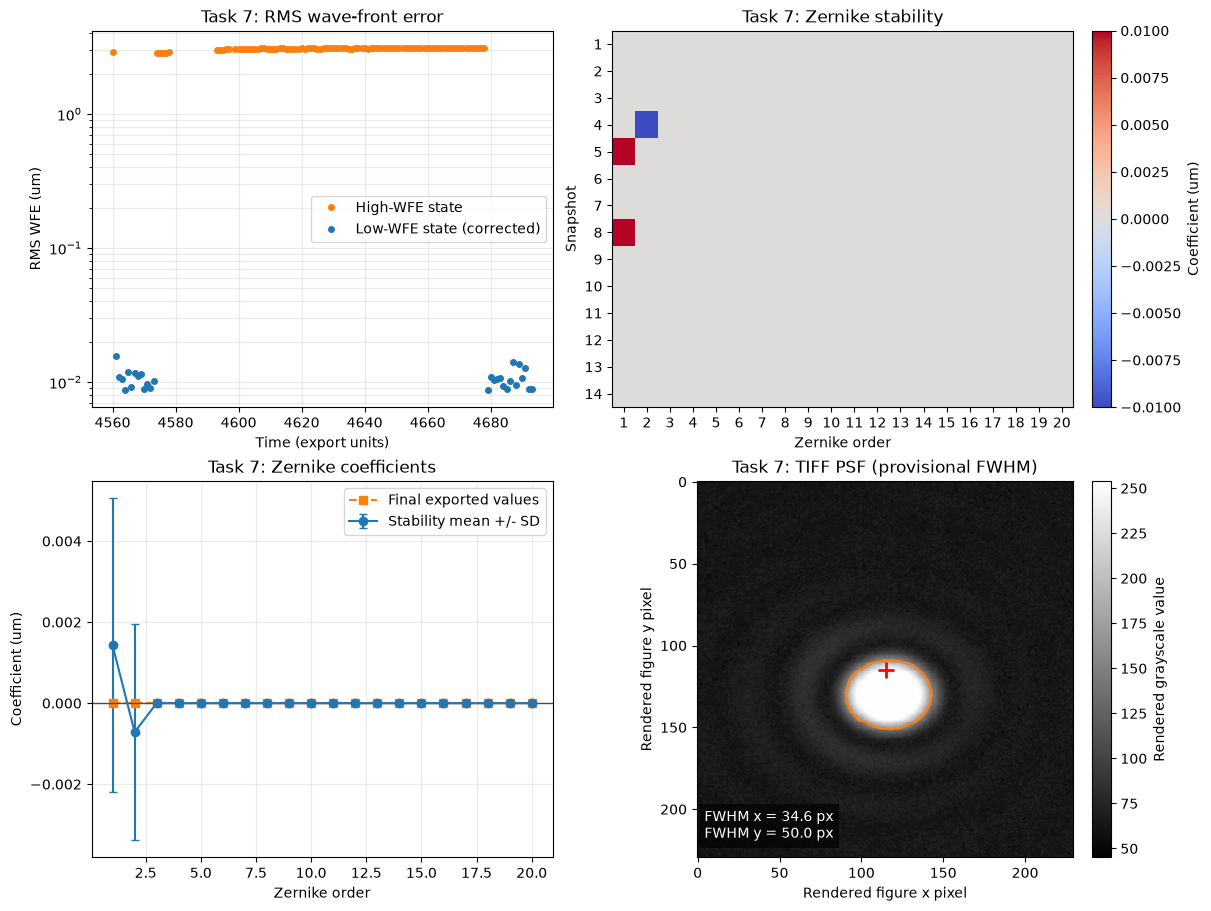

Conclusion: the low-WFE samples demonstrate a stable corrected state.  The TIFF supplies a provisional FWHM, but a new raw science-camera export is required for the final WFE-FWHM relation.


In [7]:
# TASK 7 - static wave-front correction and stability
# The low-RMS samples are treated as the observed corrected state; values below
# 1e-6 um are export underflow/sentinel values, not physical zero WFE.
def load_zernike_snapshots(filename):
    """Read one or more 20-mode Zernike exports separated by header/blank rows."""
    snapshots, current = [], []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x.strip() for x in line.split('\t') if x.strip()]
        try:
            order = int(fields[0])
            value = float(fields[1].replace(',', '.'))
        except (IndexError, ValueError):
            if current:
                snapshots.append(current)
                current = []
            continue
        if order == 1 and current:
            snapshots.append(current)
            current = []
        current.append((order, value))
    if current:
        snapshots.append(current)
    return [pd.DataFrame(block, columns=['zernike_order', 'value_um']) for block in snapshots]

task7_wfe = load_wfe('Task7_stat_wavefront_err.txt')
task7_science = load_grid('Task7_Science_camera_data.txt')
task7_wavefront_map = load_grid('Task7_Wavefront_map.txt')
task7_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task7.tif').convert('RGB'), dtype=float)
task7_tif_gray = (0.299 * task7_tif_rgb[..., 0] + 0.587 * task7_tif_rgb[..., 1]
                  + 0.114 * task7_tif_rgb[..., 2])
task7_stability = load_zernike_snapshots('Task7_system_stability.txt')
task7_final_zernike = load_zernike_snapshots('Task7_Zercike_vals.txt')[0]

# The export contains a machine-underflow sentinel (1.00747e-306) and two
# well-separated physical regimes.  The 0.1-um boundary lies in their empty gap.
underflow = task7_wfe[['p2v_um', 'rms_um']].abs().max(axis=1) < 1e-6
low_wfe = ~underflow & (task7_wfe['rms_um'] < 0.1)
high_wfe = ~underflow & ~low_wfe

def wfe_statistics(label, mask):
    values = task7_wfe.loc[mask]
    return {
        'State': label,
        'Samples': len(values),
        'P2V mean (um)': values['p2v_um'].mean(),
        'P2V SD (um)': values['p2v_um'].std(ddof=1),
        'RMS mean (um)': values['rms_um'].mean(),
        'RMS SD (um)': values['rms_um'].std(ddof=1),
        'RMS min-max (um)': (values['rms_um'].min(), values['rms_um'].max()),
    }

task7_summary = pd.DataFrame([
    wfe_statistics('Observed low-WFE state (corrected)', low_wfe),
    wfe_statistics('Observed high-WFE state', high_wfe),
])
display(task7_summary.style.format({
    'P2V mean (um)': '{:.5f}', 'P2V SD (um)': '{:.5f}',
    'RMS mean (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'RMS min-max (um)': lambda limits: f'({limits[0]:.5f}, {limits[1]:.5f})',
}))

low_rms = task7_wfe.loc[low_wfe, 'rms_um'].mean()
high_rms = task7_wfe.loc[high_wfe, 'rms_um'].mean()
print(f'RMS reduction from the observed high- to low-WFE state: {high_rms / low_rms:.1f}x')
print(f'Underflow/sentinel WFE samples excluded from statistics: {underflow.sum()}')

# The text science-camera export is invalid: it has no intensity variation and
# is identical to the saved wave-front map.  Task7.tif is a MATLAB figure rather
# than raw camera data, so the FWHM below is explicitly a provisional estimate.
camera_has_signal = np.count_nonzero(np.nan_to_num(task7_science, nan=0.0)) > 0
camera_matches_wavefront_map = np.array_equal(
    np.nan_to_num(task7_science, nan=0.0), np.nan_to_num(task7_wavefront_map, nan=0.0)
)
print(f'Science-camera text export has non-zero signal: {camera_has_signal}')
print(f'Science-camera export identical to wave-front map: {camera_matches_wavefront_map}')

def fwhm_from_rendered_profile(profile, peak_index, background):
    """Half-height width in screen pixels for a MATLAB-rendered TIFF profile."""
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)
    left_index = np.where(profile[:peak_index] < half)[0][-1]
    right_index = peak_index + 1 + np.where(profile[peak_index + 1:] < half)[0][0]
    left = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right = right_index - 1 + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1])
    return dict(width_screen_px=right - left, left_screen_px=left, right_screen_px=right, half=half)

# Locate the bright core inside the known plotted-image region.
search_y, search_x = slice(600, 950), slice(500, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task7_tif_gray[search_y, search_x]),
                                  task7_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task7_tif_gray[120:250, 500:600].ravel(),
                           task7_tif_gray[1050:1150, 500:600].ravel(),
                           task7_tif_gray[120:250, 1200:1300].ravel()]
task7_tif_background = np.median(background_samples)
task7_tif_fwhm_x_screen = fwhm_from_rendered_profile(task7_tif_gray[peak_y, :], peak_x, task7_tif_background)
task7_tif_fwhm_y_screen = fwhm_from_rendered_profile(task7_tif_gray[:, peak_x], peak_y, task7_tif_background)

# Calibrated from the 200-pixel tick separation in the rendered axes.
TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task7_tif_fwhm_x = task7_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task7_tif_fwhm_y = task7_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task7.tif rendered MATLAB figure (provisional)',
    'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task7_tif_fwhm_x,
    'FWHM y (data px)': task7_tif_fwhm_y,
}])
display(tif_fwhm_summary.style.format({'Peak plotted value (%)': '{:.3f}',
                                       'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))
print('Task 7 provisional FWHM is measured from the rendered TIFF; replace it with a raw science-camera frame after remeasurement.')

orders = task7_stability[0]['zernike_order'].to_numpy()
stability_coefficients = np.vstack([snapshot['value_um'].to_numpy() for snapshot in task7_stability])
zernike_mean = stability_coefficients.mean(axis=0)
zernike_sd = stability_coefficients.std(axis=0, ddof=1)
print(f'Zernike stability snapshots: {len(task7_stability)}; modes per snapshot: {len(orders)}')
print(f'Largest recorded Zernike coefficient magnitude: {np.abs(stability_coefficients).max():.3f} um')

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
ax = axes[0, 0]
ax.semilogy(task7_wfe.loc[high_wfe, 'time'], task7_wfe.loc[high_wfe, 'rms_um'],
            'o', ms=4, color='tab:orange', label='High-WFE state')
ax.semilogy(task7_wfe.loc[low_wfe, 'time'], task7_wfe.loc[low_wfe, 'rms_um'],
            'o', ms=4, color='tab:blue', label='Low-WFE state (corrected)')
ax.set(title='Task 7: RMS wave-front error', xlabel='Time (export units)', ylabel='RMS WFE (um)')
ax.grid(alpha=0.25, which='both'); ax.legend()

ax = axes[0, 1]
coefficient_limit = max(np.abs(stability_coefficients).max(), 0.01)
im = ax.imshow(stability_coefficients, aspect='auto', cmap='coolwarm',
               vmin=-coefficient_limit, vmax=coefficient_limit)
ax.set(title='Task 7: Zernike stability', xlabel='Zernike order', ylabel='Snapshot')
ax.set_xticks(np.arange(len(orders))); ax.set_xticklabels(orders)
ax.set_yticks(np.arange(len(task7_stability))); ax.set_yticklabels(np.arange(1, len(task7_stability) + 1))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Coefficient (um)')

ax = axes[1, 0]
ax.errorbar(orders, zernike_mean, yerr=zernike_sd, fmt='o-', capsize=3,
            color='tab:blue', label='Stability mean +/- SD')
ax.plot(task7_final_zernike['zernike_order'], task7_final_zernike['value_um'],
        's--', color='tab:orange', label='Final exported values')
ax.axhline(0, color='0.3', lw=1)
ax.set(title='Task 7: Zernike coefficients', xlabel='Zernike order', ylabel='Coefficient (um)')
ax.grid(alpha=0.25); ax.legend()

ax = axes[1, 1]
crop = 115
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task7_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.contour(task7_tif_gray[y0:y1, x0:x1], levels=[task7_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 7: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task7_tif_fwhm_x:.1f} px\nFWHM y = {task7_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')
plt.show()

print('Conclusion: the low-WFE samples demonstrate a stable corrected state.  The TIFF supplies a provisional FWHM, but a new raw science-camera export is required for the final WFE-FWHM relation.')

#### Task 8
[taken from Max's branch, just re-running it with wavelength = 635nm]

In [8]:
task_8_1_p2v = 0.589
task_8_1_rms = 0.141
task_8_2_p2v = 0.552
task_8_2_rms = 0.100
task_8_3_p2v = 0.375
task_8_3_rms = 0.100
task_8_4_p2v = 0.879
task_8_4_rms = 0.139
task_8_5_p2v = 0.701
task_8_5_rms = 0.143

strehl_8_1 = np.exp(-(2 * np.pi * task_8_1_rms / WAVELENGTH_UM) ** 2)
strehl_8_2 = np.exp(-(2 * np.pi * task_8_2_rms / WAVELENGTH_UM) ** 2)
strehl_8_3 = np.exp(-(2 * np.pi * task_8_3_rms / WAVELENGTH_UM) ** 2)
strehl_8_4 = np.exp(-(2 * np.pi * task_8_4_rms / WAVELENGTH_UM) ** 2)
strehl_8_5 = np.exp(-(2 * np.pi * task_8_5_rms / WAVELENGTH_UM) ** 2)   

print(f"Task 8.1 Strehl: {strehl_8_1:.3g}")
print(f"Task 8.2 Strehl: {strehl_8_2:.3g}")
print(f"Task 8.3 Strehl: {strehl_8_3:.3g}")
print(f"Task 8.4 Strehl: {strehl_8_4:.3g}")
print(f"Task 8.5 Strehl: {strehl_8_5:.3g}")

Task 8.1 Strehl: 0.143
Task 8.2 Strehl: 0.376
Task 8.3 Strehl: 0.376
Task 8.4 Strehl: 0.151
Task 8.5 Strehl: 0.135


In [107]:
# for report, only looking at attempts 2-5
RMS_task8 = [task_8_2_rms, task_8_3_rms, task_8_4_rms, task_8_5_rms]
strehl_task8 = [strehl_8_2, strehl_8_3, strehl_8_4, strehl_8_5]
 # strehle ratio uncertainty = 2*RMS*[ (2*pi*RMS/lambda)^2 ] *S*err_RMS
errRMS_task8 = [0.002, 0.001, 0.004, 0.003]

errStrehl_task8 = []
for (i, (rms, strehl, err_rms)) in enumerate(zip(RMS_task8, strehl_task8, errRMS_task8)):

    errStrehl = 2*rms*err_rms*strehl*((2*np.pi*rms/WAVELENGTH_UM)**2)
    
    errStrehl_task8.append(errStrehl)
    print(f'Attempt {i}: S = {strehl} ± {errStrehl}')
    print(f'Attempt {i}: S = {strehl:.4g} ± {errStrehl:.2g}')
    print(f'Attempt {i}: S = {strehl:.4g} ± {errStrehl:.5f}\n')
#errS_task7 = 2*(task7_summary['RMS mean (um)'][0])*((2*np.pi*(task7_summary['RMS mean (um)'][0])/WAVELENGTH_UM)**2)*task7_strehle*(task7_summary['RMS SD (um)'][0])
#print(f'Task7: S = {task7_strehle} ± {errS_task7}')
#print(f'Task7: S = {task7_strehle:.8f} ± {errS_task7:.8f}')
#print(f'Task7: S = {task7_strehle:.7f} ± {errS_task7:.7f}')

Attempt 0: S = 0.37566153467768004 ± 0.00014711908184164427
Attempt 0: S = 0.3757 ± 0.00015
Attempt 0: S = 0.3757 ± 0.00015

Attempt 1: S = 0.37566153467768004 ± 7.355954092082214e-05
Attempt 1: S = 0.3757 ± 7.4e-05
Attempt 1: S = 0.3757 ± 0.00007

Attempt 2: S = 0.1508220220111791 ± 0.0003172571604124558
Attempt 2: S = 0.1508 ± 0.00032
Attempt 2: S = 0.1508 ± 0.00032

Attempt 3: S = 0.13505225181675015 ± 0.00023199225096767932
Attempt 3: S = 0.1351 ± 0.00023
Attempt 3: S = 0.1351 ± 0.00023



### Task 3 & 4: saving plots from above as pdfs

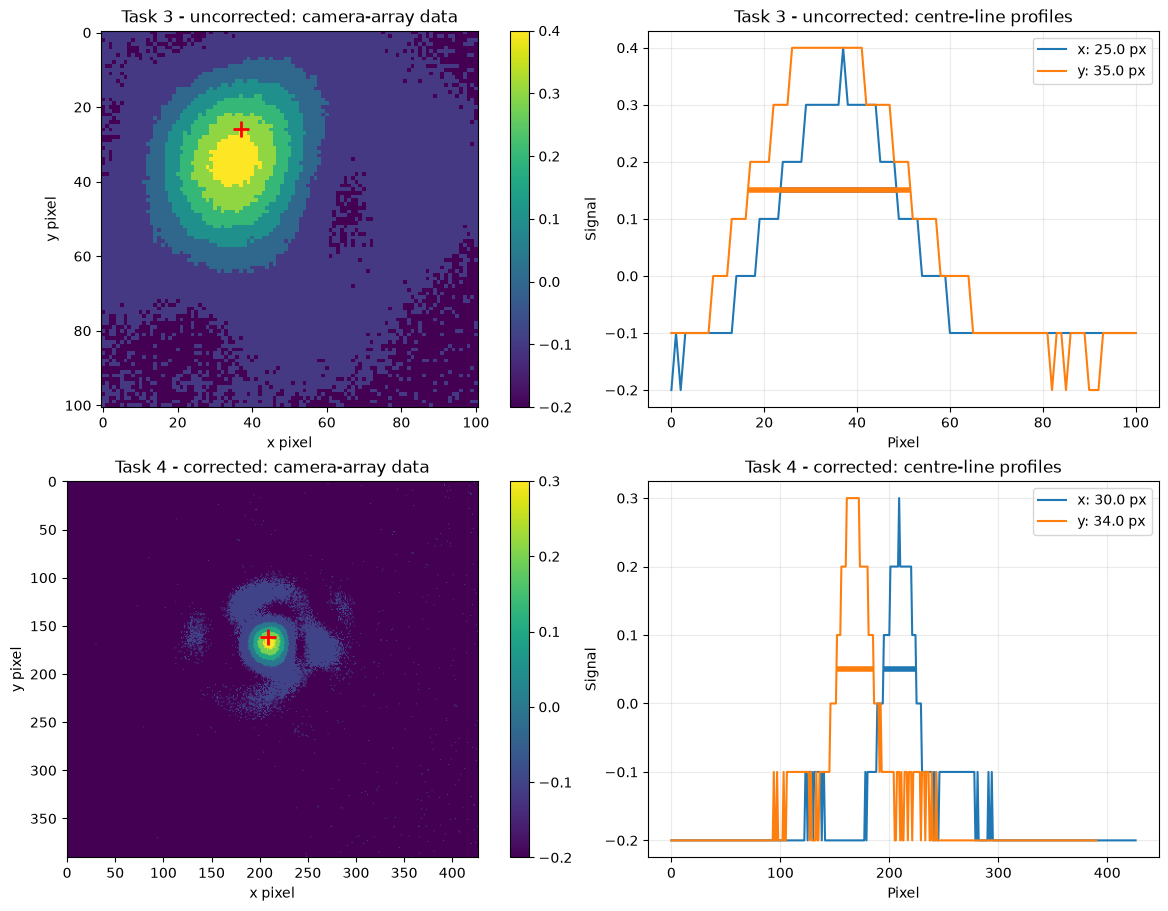

In [9]:
# Camera-array heatmaps and central FWHM profiles
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
['a) ', 'b) ', 'c) ', 'd) '] # need to change title on plots
for row, state in enumerate([task3, task4]):
    ax = axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f"{state['label']}: camera-array data") # change title
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px") # add anything to labels? e.g. FWHM in x
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4) # add anything to labels? e.g. FWHM in y
    ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal') # change title
    ax.legend(); ax.grid(alpha=0.25)
plt.show()

Going to try & change it so that it's now split into 2 plots (1 for Task 3 & 1 for Task 4)
### Note: Has there been any analysis been done on the TIF files/the Science Images themselves ???
- Want to label the files below as:
- a) 'Uncorrected/Etc' Science Image (... & then b) )

BUT it's actually the WFE maps that are being analysed ... (also don't seem to have TIF file saved for Task 4)
-> can work around, just need to know what we're *saying* in report / in fig. titles   
- label plot a) as "Wave Front Error Map", & provide Science Image for Task 3 separately

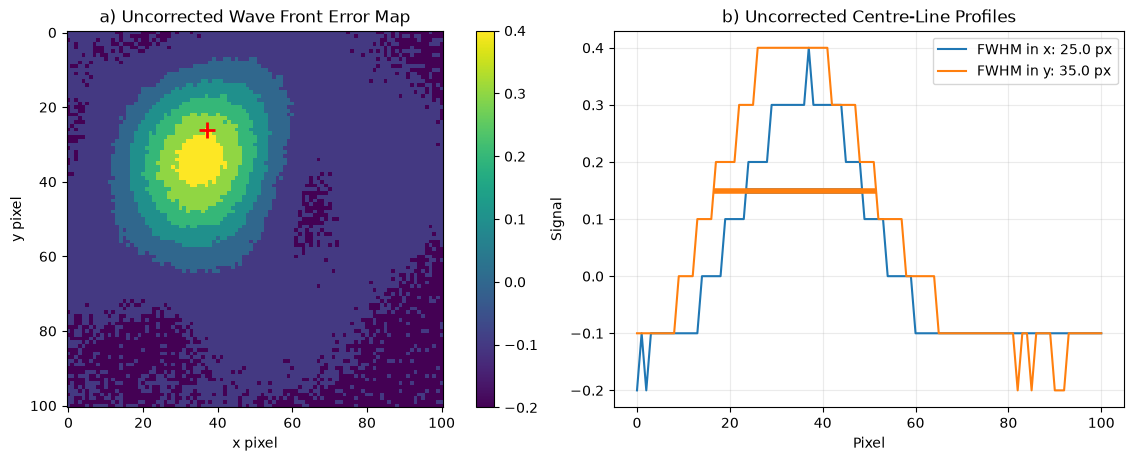

In [10]:
# Camera-array heatmaps and central FWHM profiles
    # task 3
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
#['a) ', 'b) ', 'c) ', 'd) '] # need to change title on plots
for row, state in enumerate([task3]):
    ax = axes[0] # axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f'a) Uncorrected Wave Front Error Map' ) # f"{state['label']}: camera-array data") # change title
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[1] # axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"FWHM in {axis_name}: {result['width_px']:.1f} px") # add anything to labels? e.g. FWHM in x
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4) # add anything to labels? e.g. FWHM in y
    ax.set(title=f"b) Uncorrected Centre-Line Profiles", # f"{state['label']}: centre-line profiles", 
           xlabel='Pixel', ylabel='Signal') # change title
    ax.legend(); ax.grid(alpha=0.25)
plt.show()
#fig.savefig('Analysis_plots/analysis_WFEmap_FWHM_task3.pdf', bbox_inches='tight');

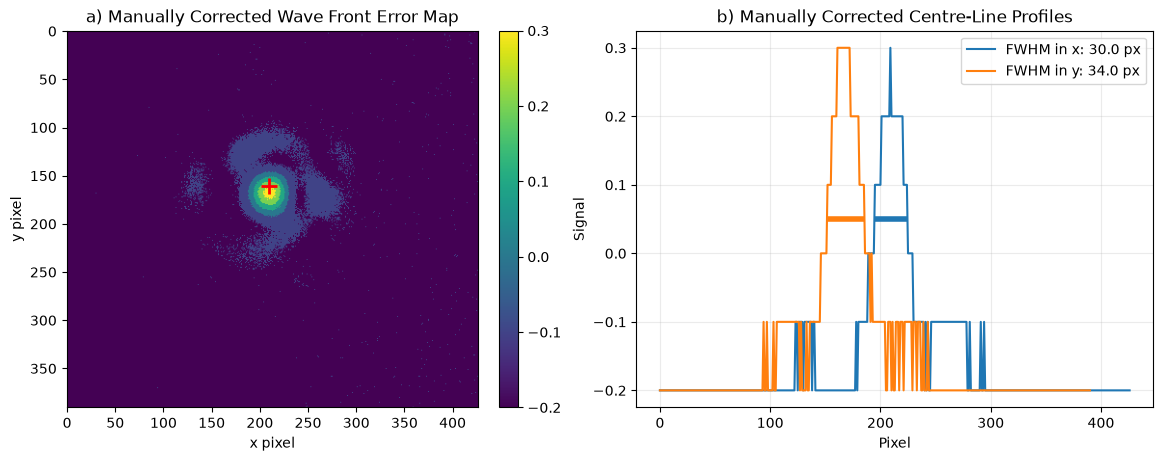

In [11]:
# Camera-array heatmaps and central FWHM profiles
    # task 4
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
#['a) ', 'b) ', 'c) ', 'd) '] # need to change title on plots
for row, state in enumerate([task4]):
    ax = axes[0] # axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f'a) Manually Corrected Wave Front Error Map' ) # f"{state['label']}: camera-array data") # change title
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[1] # axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"FWHM in {axis_name}: {result['width_px']:.1f} px") # add anything to labels? e.g. FWHM in x
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4) # add anything to labels? e.g. FWHM in y
    ax.set(title=f"b) Manually Corrected Centre-Line Profiles", # f"{state['label']}: centre-line profiles", 
           xlabel='Pixel', ylabel='Signal') # change title
    ax.legend(); ax.grid(alpha=0.25)
plt.show()
#fig.savefig('Analysis_plots/analysis_WFEmap_FWHM_task4.pdf', bbox_inches='tight');

#### Showing Science Image for Task 3 [uncorrected]

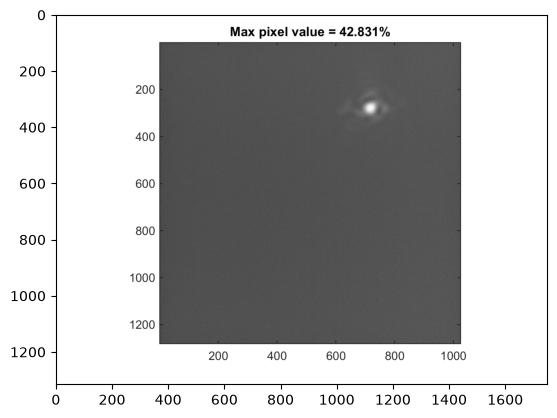

In [94]:
DATA_DIR
task3_sciImg =  plt.imread('Data/Tues0/Task3_Science_image.tif')  #Image.open('Data/Tues0/Task3_Science_image.tif') #
plt.imshow(task3_sciImg);
#task3_sciImg.show()


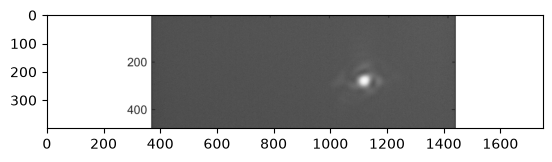

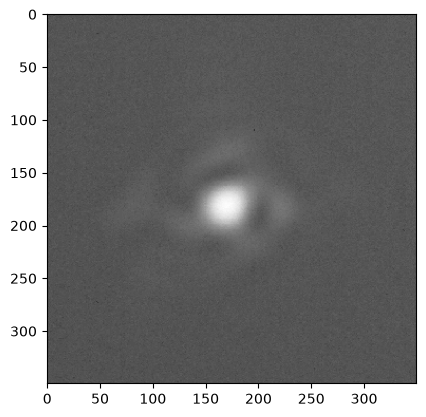

In [95]:
plt.imshow(task3_sciImg[100:500, :]);
plt.figure()
plt.imshow(task3_sciImg[150:500, 950:1300]);

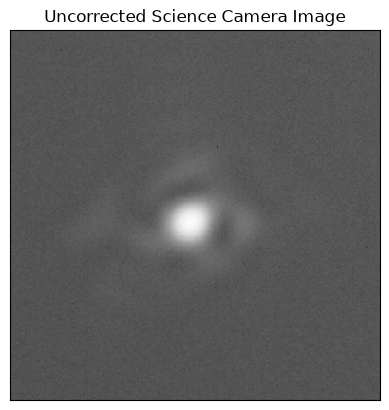

In [96]:
task3_sciImg_cropped = task3_sciImg[150:500, 950:1300]
plt.imshow(task3_sciImg_cropped);
plt.xticks([])
plt.yticks([])
plt.title('Uncorrected Science Camera Image');

In [97]:
task3_sciImg_cropped

array([[[75, 75, 75],
        [92, 92, 92],
        [81, 81, 81],
        ...,
        [92, 92, 92],
        [86, 86, 86],
        [86, 86, 86]],

       [[81, 81, 81],
        [86, 86, 86],
        [81, 81, 81],
        ...,
        [92, 92, 92],
        [92, 92, 92],
        [92, 92, 92]],

       [[81, 81, 81],
        [92, 92, 92],
        [81, 81, 81],
        ...,
        [92, 92, 92],
        [92, 92, 92],
        [92, 92, 92]],

       ...,

       [[81, 81, 81],
        [86, 86, 86],
        [81, 81, 81],
        ...,
        [92, 92, 92],
        [86, 86, 86],
        [81, 81, 81]],

       [[75, 75, 75],
        [86, 86, 86],
        [86, 86, 86],
        ...,
        [86, 86, 86],
        [86, 86, 86],
        [81, 81, 81]],

       [[75, 75, 75],
        [81, 81, 81],
        [75, 75, 75],
        ...,
        [86, 86, 86],
        [86, 86, 86],
        [75, 75, 75]]], shape=(350, 350, 3), dtype=uint8)

<Figure size 640x480 with 0 Axes>

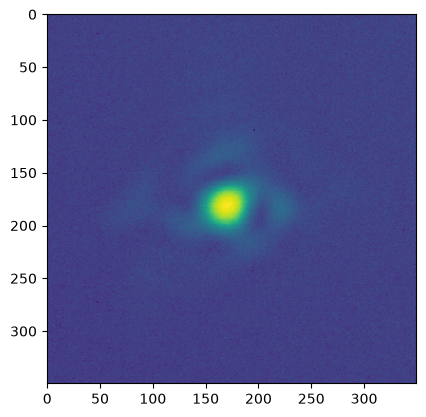

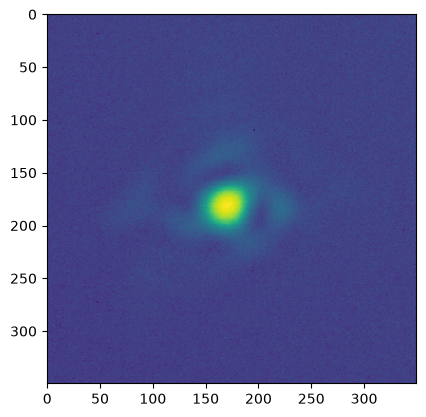

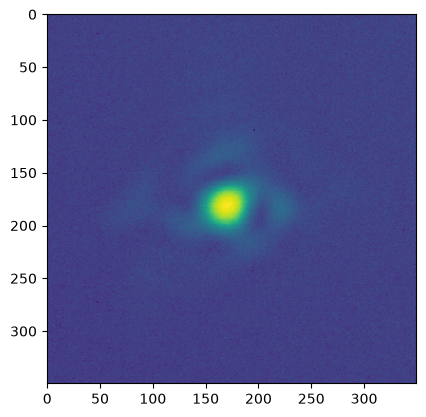

<Figure size 640x480 with 0 Axes>

In [98]:
plt.imshow(task3_sciImg_cropped[:,:,0]); # Red channel
plt.figure()
plt.imshow(task3_sciImg_cropped[:,:,1]); # B channel
plt.figure()
plt.imshow(task3_sciImg_cropped[:,:,2]); # G channel
plt.figure()

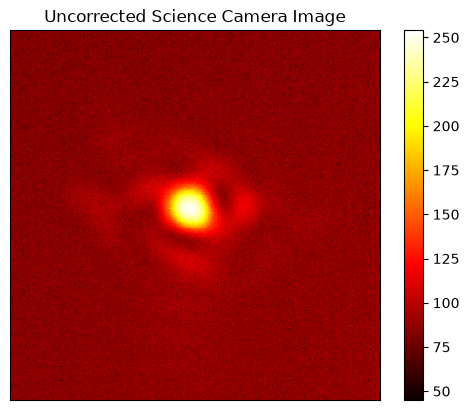

In [100]:
task3_sciImg_cropped = task3_sciImg[150:500, 950:1300]
plt.imshow(np.mean(task3_sciImg_cropped, axis=2), cmap='hot', origin='lower'); # easiest to just collapse image into greyscale for moment, & apply colormap
# set image origin as 'lower' so that it's orientated like how a plot would be / so x&Y lie along their expected axes
plt.colorbar();
plt.xticks([])
plt.yticks([])
plt.title('Uncorrected Science Camera Image');
#plt.savefig('Analysis_plots/analysis_sciImg_task3.pdf');

### Task 7

In [18]:
# TASK 7 - static wave-front correction and stability
# The low-RMS samples are treated as the observed corrected state; values below
# 1e-6 um are export underflow/sentinel values, not physical zero WFE.
def load_zernike_snapshots(filename):
    """Read one or more 20-mode Zernike exports separated by header/blank rows."""
    snapshots, current = [], []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x.strip() for x in line.split('\t') if x.strip()]
        try:
            order = int(fields[0])
            value = float(fields[1].replace(',', '.'))
        except (IndexError, ValueError):
            if current:
                snapshots.append(current)
                current = []
            continue
        if order == 1 and current:
            snapshots.append(current)
            current = []
        current.append((order, value))
    if current:
        snapshots.append(current)
    return [pd.DataFrame(block, columns=['zernike_order', 'value_um']) for block in snapshots]

In [19]:
task7_wfe = load_wfe('Task7_stat_wavefront_err.txt')
task7_science = load_grid('Task7_Science_camera_data.txt')
task7_wavefront_map = load_grid('Task7_Wavefront_map.txt')
task7_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task7.tif').convert('RGB'), dtype=float)
task7_tif_gray = (0.299 * task7_tif_rgb[..., 0] + 0.587 * task7_tif_rgb[..., 1]
                  + 0.114 * task7_tif_rgb[..., 2])
task7_stability = load_zernike_snapshots('Task7_system_stability.txt')
task7_final_zernike = load_zernike_snapshots('Task7_Zercike_vals.txt')[0]

In [20]:
# The export contains a machine-underflow sentinel (1.00747e-306) and two
# well-separated physical regimes.  The 0.1-um boundary lies in their empty gap.
underflow = task7_wfe[['p2v_um', 'rms_um']].abs().max(axis=1) < 1e-6
low_wfe = ~underflow & (task7_wfe['rms_um'] < 0.1)
high_wfe = ~underflow & ~low_wfe

def wfe_statistics(label, mask):
    values = task7_wfe.loc[mask]
    return {
        'State': label,
        'Samples': len(values),
        'P2V mean (um)': values['p2v_um'].mean(),
        'P2V SD (um)': values['p2v_um'].std(ddof=1),
        'RMS mean (um)': values['rms_um'].mean(),
        'RMS SD (um)': values['rms_um'].std(ddof=1),
        'RMS min-max (um)': (values['rms_um'].min(), values['rms_um'].max()),
    }

task7_summary = pd.DataFrame([
    wfe_statistics('Observed low-WFE state (corrected)', low_wfe),
    wfe_statistics('Observed high-WFE state', high_wfe),
])
display(task7_summary.style.format({
    'P2V mean (um)': '{:.5f}', 'P2V SD (um)': '{:.5f}',
    'RMS mean (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'RMS min-max (um)': lambda limits: f'({limits[0]:.5f}, {limits[1]:.5f})',
}))

low_rms = task7_wfe.loc[low_wfe, 'rms_um'].mean()
high_rms = task7_wfe.loc[high_wfe, 'rms_um'].mean()
print(f'RMS reduction from the observed high- to low-WFE state: {high_rms / low_rms:.1f}x')
print(f'Underflow/sentinel WFE samples excluded from statistics: {underflow.sum()}')

,State,Samples,P2V mean (um),P2V SD (um),RMS mean (um),RMS SD (um),RMS min-max (um)
0,Observed low-WFE state (corrected),28,0.07297,0.00820,0.01060,0.00176,"(0.00871, 0.01572)"
1,Observed high-WFE state,91,12.14470,0.20738,3.07692,0.05840,"(2.84197, 3.12090)"


RMS reduction from the observed high- to low-WFE state: 290.3x
Underflow/sentinel WFE samples excluded from statistics: 45


In [21]:
task7_summary['RMS mean (um)'][0], task7_summary['RMS SD (um)'][0]

(np.float64(0.010599598214285714), np.float64(0.0017582734326059197))

In [22]:
task7_strehle = np.exp(-(2 * np.pi * task7_summary['RMS mean (um)'][0] / WAVELENGTH_UM) ** 2)
task7_strehle

np.float64(0.9890603186667668)

In [23]:
 # strehle ratio uncertainty = 2*RMS*[ (2*pi*RMS/lambda)^2 ] *S*err_RMS
errS_task7 = 2*(task7_summary['RMS mean (um)'][0])*((2*np.pi*(task7_summary['RMS mean (um)'][0])/WAVELENGTH_UM)**2)*task7_strehle*(task7_summary['RMS SD (um)'][0])
print(f'Task7: S = {task7_strehle} ± {errS_task7}')
print(f'Task7: S = {task7_strehle:.8f} ± {errS_task7:.8f}')
print(f'Task7: S = {task7_strehle:.7f} ± {errS_task7:.7f}')

Task7: S = 0.9890603186667668 ± 4.055269151296141e-07
Task7: S = 0.98906032 ± 0.00000041
Task7: S = 0.9890603 ± 0.0000004


In [24]:
# The text science-camera export is invalid: it has no intensity variation and
# is identical to the saved wave-front map.  Task7.tif is a MATLAB figure rather
# than raw camera data, so the FWHM below is explicitly a provisional estimate.
camera_has_signal = np.count_nonzero(np.nan_to_num(task7_science, nan=0.0)) > 0
camera_matches_wavefront_map = np.array_equal(
    np.nan_to_num(task7_science, nan=0.0), np.nan_to_num(task7_wavefront_map, nan=0.0)
)
print(f'Science-camera text export has non-zero signal: {camera_has_signal}')
print(f'Science-camera export identical to wave-front map: {camera_matches_wavefront_map}')

Science-camera text export has non-zero signal: False
Science-camera export identical to wave-front map: True


In [25]:
def fwhm_from_rendered_profile(profile, peak_index, background):
    """Half-height width in screen pixels for a MATLAB-rendered TIFF profile."""
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)
    left_index = np.where(profile[:peak_index] < half)[0][-1]
    right_index = peak_index + 1 + np.where(profile[peak_index + 1:] < half)[0][0]
    left = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right = right_index - 1 + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1])
    return dict(width_screen_px=right - left, left_screen_px=left, right_screen_px=right, half=half)

In [26]:
# Locate the bright core inside the known plotted-image region.
search_y, search_x = slice(600, 950), slice(500, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task7_tif_gray[search_y, search_x]),
                                  task7_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task7_tif_gray[120:250, 500:600].ravel(),
                           task7_tif_gray[1050:1150, 500:600].ravel(),
                           task7_tif_gray[120:250, 1200:1300].ravel()]
task7_tif_background = np.median(background_samples)
task7_tif_fwhm_x_screen = fwhm_from_rendered_profile(task7_tif_gray[peak_y, :], peak_x, task7_tif_background)
task7_tif_fwhm_y_screen = fwhm_from_rendered_profile(task7_tif_gray[:, peak_x], peak_y, task7_tif_background)

# Calibrated from the 200-pixel tick separation in the rendered axes.
TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task7_tif_fwhm_x = task7_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task7_tif_fwhm_y = task7_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task7.tif rendered MATLAB figure (provisional)',
    'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task7_tif_fwhm_x,
    'FWHM y (data px)': task7_tif_fwhm_y,
}])
display(tif_fwhm_summary.style.format({'Peak plotted value (%)': '{:.3f}',
                                       'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))
print('Task 7 provisional FWHM is measured from the rendered TIFF; replace it with a raw science-camera frame after remeasurement.')

orders = task7_stability[0]['zernike_order'].to_numpy()
stability_coefficients = np.vstack([snapshot['value_um'].to_numpy() for snapshot in task7_stability])
zernike_mean = stability_coefficients.mean(axis=0)
zernike_sd = stability_coefficients.std(axis=0, ddof=1)
print(f'Zernike stability snapshots: {len(task7_stability)}; modes per snapshot: {len(orders)}')
print(f'Largest recorded Zernike coefficient magnitude: {np.abs(stability_coefficients).max():.3f} um')

,FWHM source,Peak plotted value (%),FWHM x (data px),FWHM y (data px)
0,Task7.tif rendered MATLAB figure (provisional),84.468,34.6,50.0


Task 7 provisional FWHM is measured from the rendered TIFF; replace it with a raw science-camera frame after remeasurement.
Zernike stability snapshots: 14; modes per snapshot: 20
Largest recorded Zernike coefficient magnitude: 0.010 um


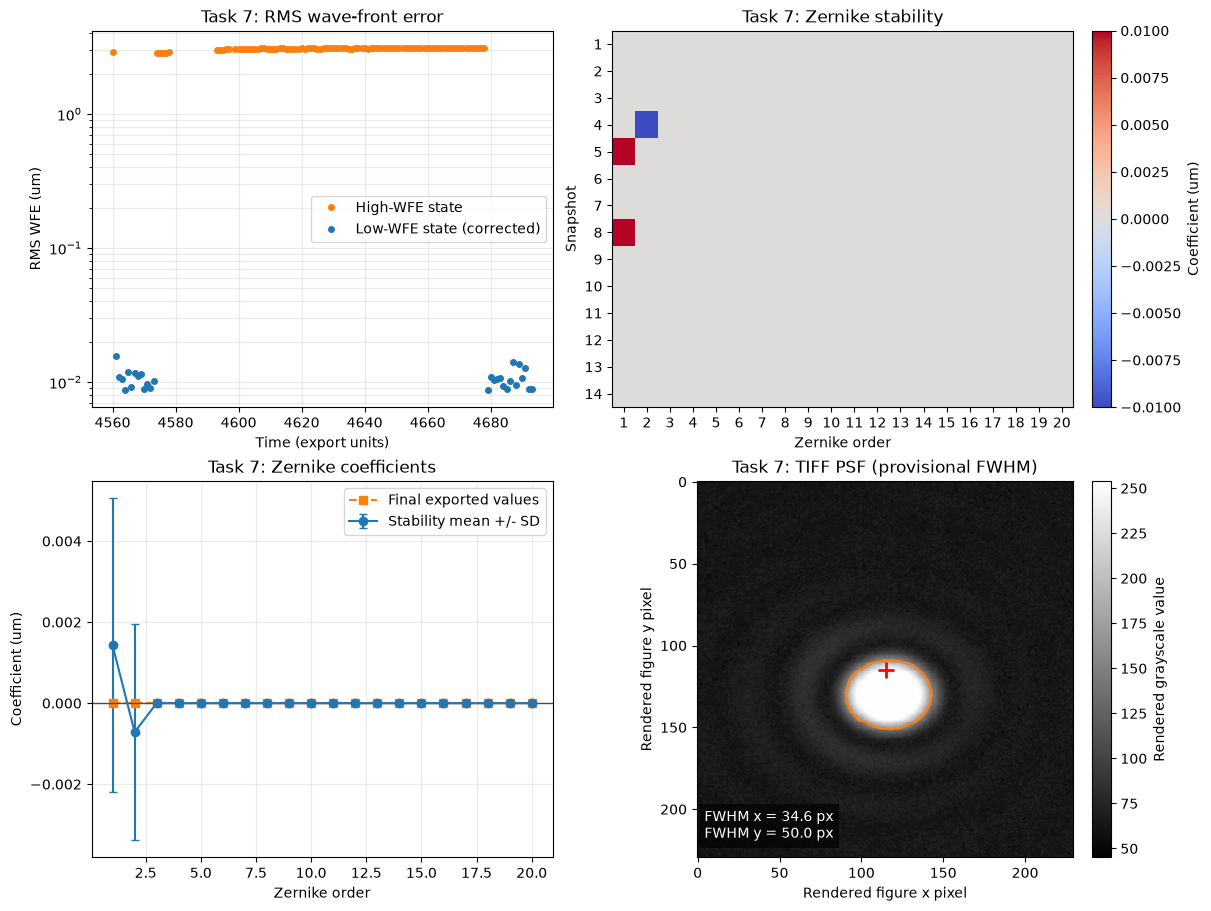

Conclusion: the low-WFE samples demonstrate a stable corrected state.  The TIFF supplies a provisional FWHM, but a new raw science-camera export is required for the final WFE-FWHM relation.


In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
ax = axes[0, 0]
ax.semilogy(task7_wfe.loc[high_wfe, 'time'], task7_wfe.loc[high_wfe, 'rms_um'],
            'o', ms=4, color='tab:orange', label='High-WFE state')
ax.semilogy(task7_wfe.loc[low_wfe, 'time'], task7_wfe.loc[low_wfe, 'rms_um'],
            'o', ms=4, color='tab:blue', label='Low-WFE state (corrected)')
ax.set(title='Task 7: RMS wave-front error', xlabel='Time (export units)', ylabel='RMS WFE (um)')
ax.grid(alpha=0.25, which='both'); ax.legend()

ax = axes[0, 1]
coefficient_limit = max(np.abs(stability_coefficients).max(), 0.01)
im = ax.imshow(stability_coefficients, aspect='auto', cmap='coolwarm',
               vmin=-coefficient_limit, vmax=coefficient_limit)
ax.set(title='Task 7: Zernike stability', xlabel='Zernike order', ylabel='Snapshot')
ax.set_xticks(np.arange(len(orders))); ax.set_xticklabels(orders)
ax.set_yticks(np.arange(len(task7_stability))); ax.set_yticklabels(np.arange(1, len(task7_stability) + 1))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Coefficient (um)')

ax = axes[1, 0]
ax.errorbar(orders, zernike_mean, yerr=zernike_sd, fmt='o-', capsize=3,
            color='tab:blue', label='Stability mean +/- SD')
ax.plot(task7_final_zernike['zernike_order'], task7_final_zernike['value_um'],
        's--', color='tab:orange', label='Final exported values')
ax.axhline(0, color='0.3', lw=1)
ax.set(title='Task 7: Zernike coefficients', xlabel='Zernike order', ylabel='Coefficient (um)')
ax.grid(alpha=0.25); ax.legend()

ax = axes[1, 1]
crop = 115
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task7_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.contour(task7_tif_gray[y0:y1, x0:x1], levels=[task7_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 7: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task7_tif_fwhm_x:.1f} px\nFWHM y = {task7_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')
plt.show()

print('Conclusion: the low-WFE samples demonstrate a stable corrected state.  The TIFF supplies a provisional FWHM, but a new raw science-camera export is required for the final WFE-FWHM relation.')

#### Want to show science camera image, & hopefully WFE / FWHM plots like what was done in Task 3 & 4 (consistency)

##### Load in Science camera image

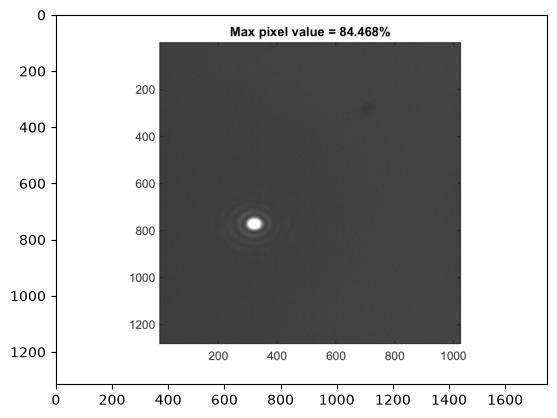

In [8]:
#DATA_DIR
task7_sciImg =  plt.imread('Data/Tues0/Task7.tif')  #Image.open('Data/Tues0/Task7_Science_image.tif') #
plt.imshow(task7_sciImg);

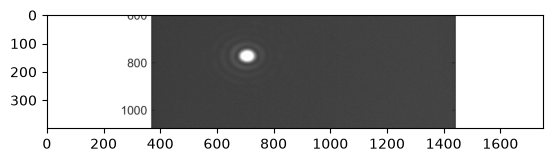

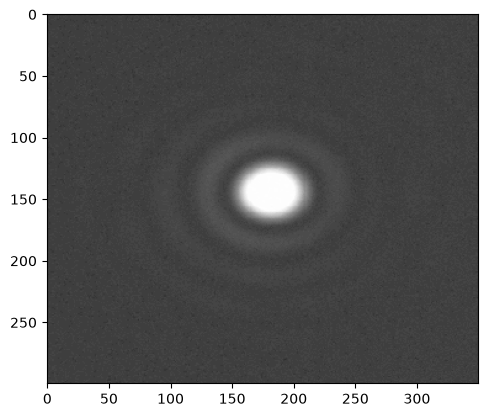

In [9]:
plt.imshow(task7_sciImg[600:1000, :]);
plt.figure()
plt.imshow(task7_sciImg[600:900, 525:875]);

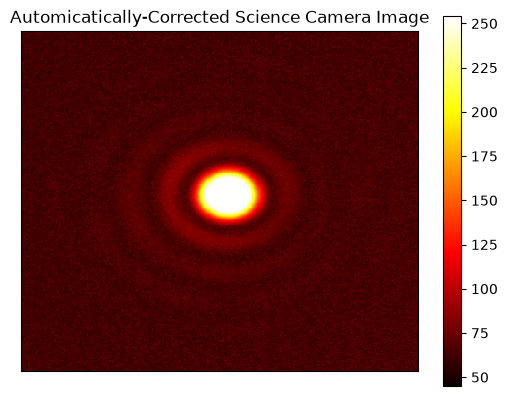

In [10]:
task7_sciImg_cropped = task7_sciImg[600:900, 525:875] # [150:500, 950:1300]
plt.imshow(np.mean(task7_sciImg_cropped, axis=2), cmap='hot'); # easiest to just collapse image into greyscale for moment, & apply colormap
plt.colorbar();
plt.xticks([])
plt.yticks([])
plt.title('Automicatically-Corrected Science Camera Image');
#plt.savefig('Analysis_plots/analysis_sciImg_task7.pdf');

#### Trying to get WFE map so can get FWHM plot => failure

In [47]:
TESTimage_task7 = load_grid('Task7_Wavefront_map.txt')
print(TESTimage_task7)

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]


In [52]:
np.nan_to_num(TESTimage_task7)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(40, 32))

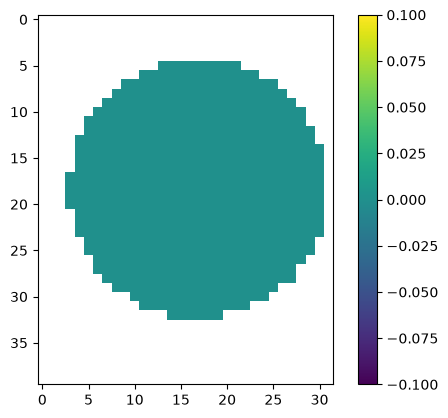

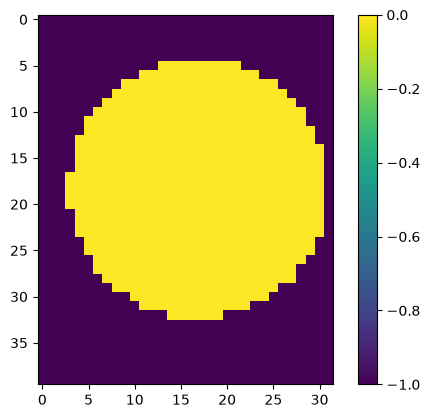

In [59]:
plt.imshow(TESTimage_task7)
plt.colorbar();
plt.figure()
plt.imshow(np.nan_to_num(TESTimage_task7, nan=-1))
plt.colorbar();

In [ ]:
 # so WFE map is genuinely unuseable, so need to look at TIF file to get FWHM map

In [44]:
task7 = analyse_state('Task 7 -  automatically corrected',
                      'Task7_stat_wavefront_err.txt',
                      'Task7_Wavefront_map.txt')

ValueError: The profile does not cross half maximum on both sides.

#### Have to get FWHM & corresponding plots from TIF file

In [ ]:
for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']) ]:
    
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px")
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
   # ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal')
   # ax.legend(); ax.grid(alpha=0.25)

# where state => e.g. task3, task 4
# task3 = analyse_state('Task 3 - uncorrected', 'Task3_stat_wavefront_err.txt', 'Task3_FWHM_raw_data.txt')

def analyse_state(label, wfe_file, image_file):
    wfe = load_wfe(wfe_file)
    image = load_grid(image_file)
    peak_row, peak_col = np.unravel_index(np.nanargmax(image), image.shape)
    x_profile = image[peak_row, :]
    y_profile = image[:, peak_col]
    rms_mean = wfe['rms_um'].mean()
    return dict(
        label=label, wfe=wfe, image=image, peak_row=peak_row, peak_col=peak_col,
        x_profile=x_profile, y_profile=y_profile, x_fwhm=fwhm(x_profile), y_fwhm=fwhm(y_profile),
        p2v_mean_um=wfe['p2v_um'].mean(), p2v_sd_um=wfe['p2v_um'].std(ddof=1),
        rms_mean_um=rms_mean, rms_sd_um=wfe['rms_um'].std(ddof=1),
        strehl_marechal=np.exp(-(2 * np.pi * rms_mean / WAVELENGTH_UM) ** 2),
    )
# so need: x_profile = image[peak_row, :]
        #  y_profile = image[:, peak_col] for plotting centre-line profiles
# => 


##### Trying with WFE map

In [63]:
task7_wfeMap = load_grid('Task7_Wavefront_map.txt')
Test7_peak_row, Test7_peak_col = np.unravel_index(np.nanargmax(task7_wfeMap), task7_wfeMap.shape)
Test7_x_profile = task7_wfeMap[Test7_peak_row, :]
Test7_y_profile = task7_wfeMap[:, Test7_peak_col]

In [65]:
Test7_x_profile

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
        0.,  0.,  0., -0., -0., -0., -0., -0., -0., nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan])

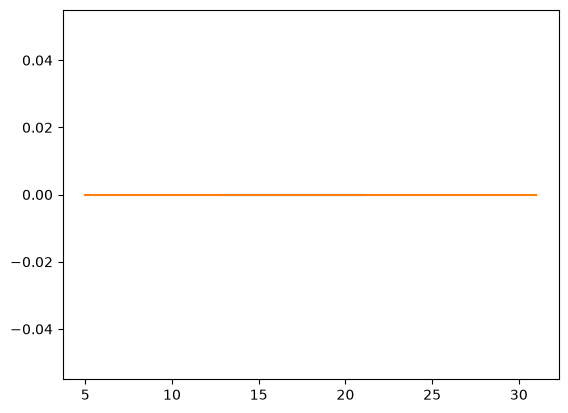

In [66]:
x = np.arange(len(Test7_x_profile))
plt.plot(x, Test7_x_profile, color='tab:blue', label=f"FWHM in x: 35.0 $\pm$ 1.0 px")
#plt.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
y = np.arange(len(Test7_y_profile))
plt.plot(y, Test7_y_profile, color='tab:orange', label=f"FWHM in y: 50.0 $\pm$ 1.0 px");
     # both lines = all zeros (or NaNs ...)

##### Now see if I can get TIF to work

In [67]:
task7_tif_gray
task7_tif_fwhm_x_screen #= fwhm_from_rendered_profile(task7_tif_gray[peak_y, :], peak_x, task7_tif_background)
task7_tif_fwhm_y_screen #= fwhm_from_rendered_profile(task7_tif_gray[:, peak_x], peak_y, task7_tif_background)

{'width_screen_px': np.float64(41.745341614906806),
 'left_screen_px': np.float64(722.9285714285714),
 'right_screen_px': np.float64(764.6739130434783),
 'half': np.float64(161.5)}

In [68]:
Test7_peak_row, Test7_peak_col = np.unravel_index(np.nanargmax(task7_tif_gray), task7_tif_gray.shape)
Test7_x_profile = task7_tif_gray[Test7_peak_row, :]
Test7_y_profile = task7_tif_gray[:, Test7_peak_col]

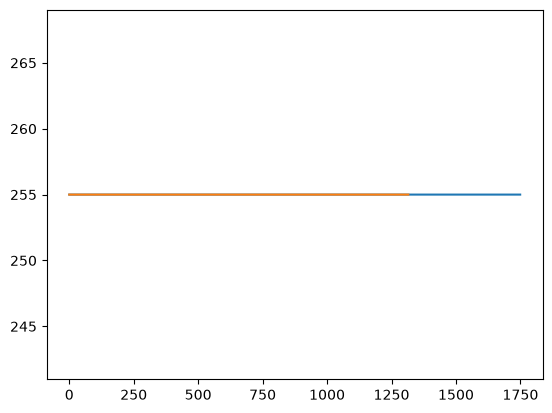

In [69]:
x = np.arange(len(Test7_x_profile))
plt.plot(x, Test7_x_profile, color='tab:blue', label=f"FWHM in x: 35.0 $\pm$ 1.0 px")
#plt.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
y = np.arange(len(Test7_y_profile))
plt.plot(y, Test7_y_profile, color='tab:orange', label=f"FWHM in y: 50.0 $\pm$ 1.0 px");
     # both lines = all zeros (or NaNs ...)

In [ ]:
# before had: 


# Camera-array heatmaps and central FWHM profiles
    # task 3
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for row, state in enumerate([task3]):
    # cutting out axes[0] # where WFE map was
    ax = axes[1] # axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"FWHM in {axis_name}: {result['width_px']:.1f} px") # add anything to labels? e.g. FWHM in x
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4) # add anything to labels? e.g. FWHM in y
    ax.set(title=f"b) Automatically-Corrected Centre-Line Profiles", 
           xlabel='Pixel', ylabel='Signal') 
    ax.legend(); ax.grid(alpha=0.25)
plt.show()
#fig.savefig('Analysis_plots/analysis_WFEmap_FWHM_task3.pdf', bbox_inches='tight');

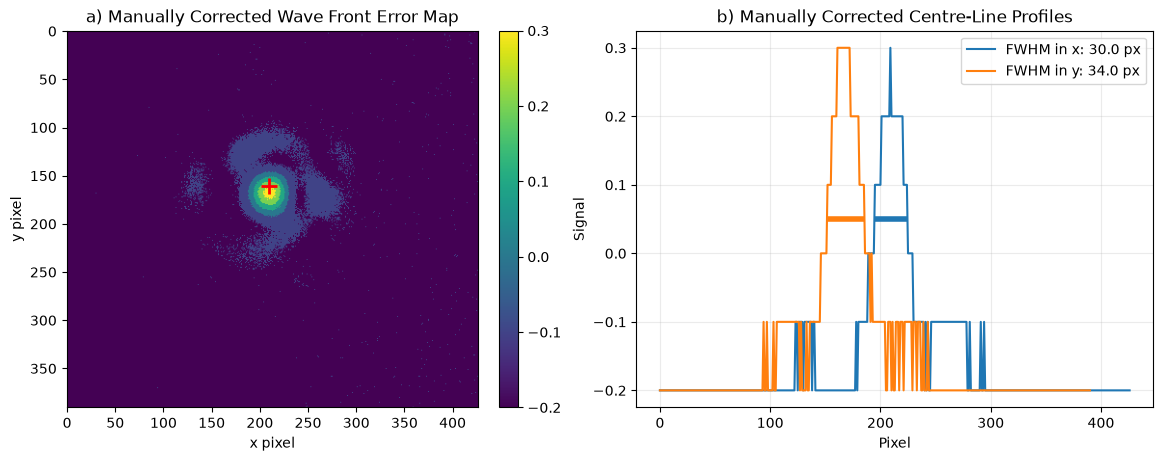

In [11]:
# Camera-array heatmaps and central FWHM profiles
    # task 7
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for row, state in enumerate([task4]):
    # could put in Zihang's science camera image plot here
    ax = axes[0] # axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f'a) Automatically-Corrected XXX-Wave Front Error Map-XXX' ) 
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[1] # axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"FWHM in {axis_name}: {result['width_px']:.1f} px") # add anything to labels? e.g. FWHM in x
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4) # add anything to labels? e.g. FWHM in y
    ax.set(title=f"b) Automatically-Corrected Centre-Line Profiles",  
           xlabel='Pixel', ylabel='Signal') # change title
    ax.legend(); ax.grid(alpha=0.25)
plt.show()
#fig.savefig('Analysis_plots/analysis_FWHM_task7.pdf', bbox_inches='tight');

#### Updated Task 7 code from Zihang's GitHub

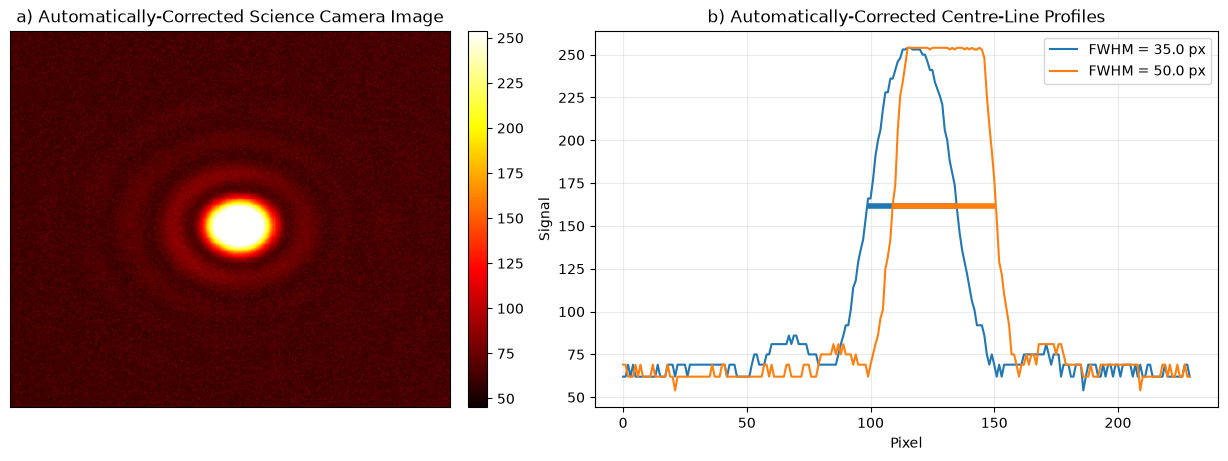

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
ax = axes[0]
im = ax.imshow(np.mean(task7_sciImg_cropped, axis=2), cmap='hot', origin='lower'); # easiest to just collapse image into greyscale for moment, & apply colormap
# set image origin as 'lower' so that it's orientated like how a plot would be / so x&Y lie along their expected axes
#ax.set_colorbar();
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('a) Automatically-Corrected Science Camera Image');
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)#, label='Rendered grayscale value');

ax = axes[1];
for profile, colour, result, width, offset in [
    (task7_tif_gray[peak_y, x0:x1], 'tab:blue', task7_tif_fwhm_x_screen, task7_tif_fwhm_x, x0),
    (task7_tif_gray[y0:y1, peak_x], 'tab:orange', task7_tif_fwhm_y_screen, task7_tif_fwhm_y, y0),
]:
    pixels = np.arange(len(profile))
    ax.plot(pixels, profile, color=colour, label=f'FWHM = {np.round(width):.1f} px') 
    # have uncertainty of 1.0px, so want right precision
    ax.hlines(result['half'], result['left_screen_px'] - offset, result['right_screen_px'] - offset,
              color=colour, lw=4)
ax.set(title='b) Automatically-Corrected Centre-Line Profiles', xlabel='Pixel', ylabel='Signal')
ax.grid(alpha=0.25); 
ax.legend();
#fig.savefig('Analysis_plots/analysis_FWHM_task7.pdf', bbox_inches='tight');

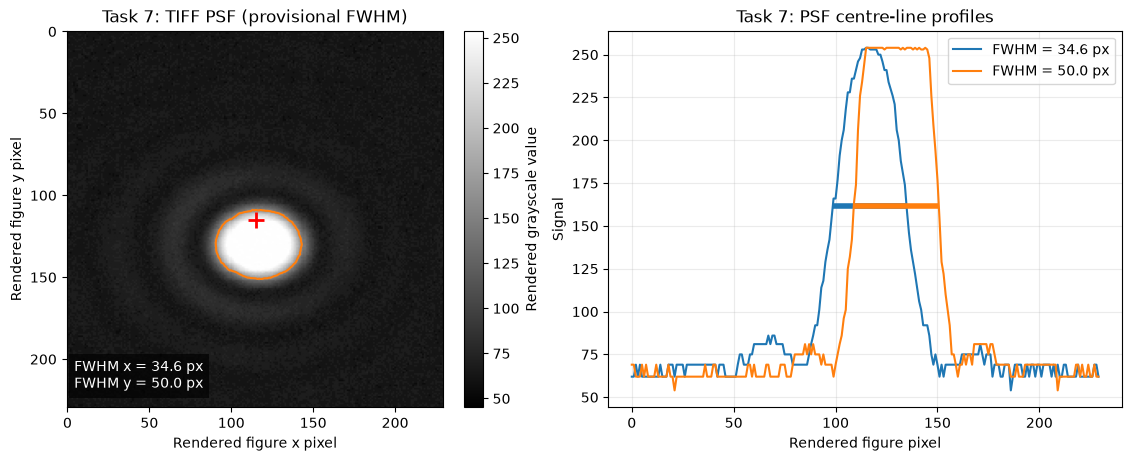

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
ax = axes[0]
crop = 115
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task7_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.contour(task7_tif_gray[y0:y1, x0:x1], levels=[task7_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 7: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task7_tif_fwhm_x:.1f} px\nFWHM y = {task7_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value');

ax = axes[1];
for profile, colour, result, width, offset in [
    (task7_tif_gray[peak_y, x0:x1], 'tab:blue', task7_tif_fwhm_x_screen, task7_tif_fwhm_x, x0),
    (task7_tif_gray[y0:y1, peak_x], 'tab:orange', task7_tif_fwhm_y_screen, task7_tif_fwhm_y, y0),
]:
    pixels = np.arange(len(profile))
    ax.plot(pixels, profile, color=colour, label=f'FWHM = {width:.1f} px')
    ax.hlines(result['half'], result['left_screen_px'] - offset, result['right_screen_px'] - offset,
              color=colour, lw=4)
ax.set(title='Task 7: PSF centre-line profiles', xlabel='Rendered figure pixel', ylabel='Signal')
ax.grid(alpha=0.25); 
ax.legend();

NameError: name 'uncorrected' is not defined

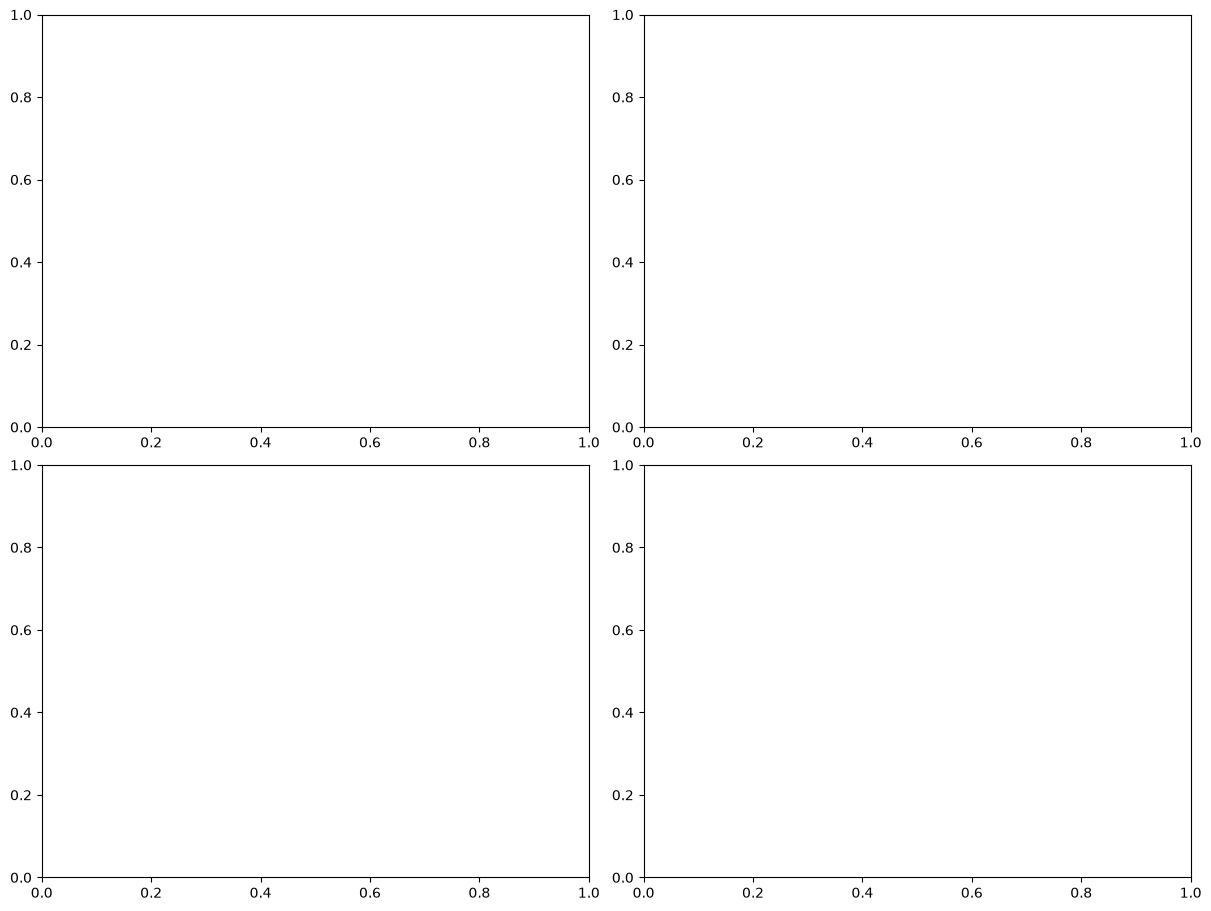

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
ax = axes[0, 0]
ax.semilogy(uncorrected['time'], uncorrected['rms_um'],
            'o', ms=4, color='tab:orange', label='Task 7 - uncorrected')
ax.semilogy(task7_wfe.loc[low_wfe, 'time'], task7_wfe.loc[low_wfe, 'rms_um'],
            'o', ms=4, color='tab:blue', label='Task 7 - corrected')
ax.set(title='Task 7: RMS wave-front error', xlabel='System time', ylabel='RMS WFE (µm)')
ax.grid(alpha=0.25, which='both'); ax.legend()

ax = axes[0, 1]
crop = 115
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task7_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.contour(task7_tif_gray[y0:y1, x0:x1], levels=[task7_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 7: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task7_tif_fwhm_x:.1f} px\nFWHM y = {task7_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')

ax = axes[1, 0]
for profile, colour, result, width, offset in [
    (task7_tif_gray[peak_y, x0:x1], 'tab:blue', task7_tif_fwhm_x_screen, task7_tif_fwhm_x, x0),
    (task7_tif_gray[y0:y1, peak_x], 'tab:orange', task7_tif_fwhm_y_screen, task7_tif_fwhm_y, y0),
]:
    pixels = np.arange(len(profile))
    ax.plot(pixels, profile, color=colour, label=f'FWHM = {width:.1f} px')
    ax.hlines(result['half'], result['left_screen_px'] - offset, result['right_screen_px'] - offset,
              color=colour, lw=4)
ax.set(title='Task 7: PSF centre-line profiles', xlabel='Rendered figure pixel', ylabel='Signal')
ax.grid(alpha=0.25); ax.legend()

ax = axes[1, 1]
for index, order in enumerate(task7_orders[:5]):
    ax.plot(np.arange(1, len(task7_zernike) + 1), task7_coefficients[:, index],
            'o-', ms=3, label=f'Z{order}')
ax.axhline(0, color='0.3', lw=1)
ax.set(title='Task 7: low-order Zernike coefficients', xlabel='Snapshot',
       ylabel='Coefficient (µm)')
ax.grid(alpha=0.25); ax.legend(ncol=2, fontsize=8)
plt.show()